# c5 · Step 5: Input experiments

Model and training are fixed to the c4 initial model. Only the **input** changes. Every option runs with 3 seeds
and the option with the highest mean val balanced accuracy wins (`lib.report.pick`), whatever its size or cost.
One exception, for validity rather than simplicity: geometry also weighs the shortcut probe (section 1).

The runs in this notebook were trained on Apple MPS in round r0 and reused by the reported round r2, which
retrains the chosen input on CUDA at the start of c6. Round r0 used the *tie rule* (an option replaced the current
choice only if it was better by more than 2·σ_seed·√(2/n), about 5 pp, see c2 and c4); "Other rounds" notes
refer to it.

| # | Question | Options |
|---|---|---|
| 1 | Geometry | stretch / pad / crop to head |
| 2 | Channels | 1 (grayscale) / 3 (as stored) |
| 3 | Normalisation | global train mean/std / per image |
| 4 | Resolution | 64 / 128 / 192 px |

**The shortcut problem.** c1 showed that size, framing and colour differ by class. A shortcut that is present
in val too *raises* the val score, so val accuracy alone would *reward* the leakiest preprocessing. The geometry
decision therefore also uses a **probe**: the same model trained and evaluated on images where the head is
blacked out (`probe=True`), so only background, borders and padding remain. A probe score near 0.25 means no
usable signal outside the head. Anything above that is signal the model could use instead of anatomy.

In [1]:
import sys, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, "..")
from dataclasses import replace
from lib.train import Config, run
from lib.report import run_seeds, compare, pick, sigma_seed, log_progress, SEEDS3, curve_test
from lib.data import ARTIFACTS, load_split
from lib.report import protocol; proto = protocol()   # c4 protocol; epoch cap = lib.report.EPOCH_CAP (60 in the reported round r2, 200 in r3)
# at c4's 60-epoch cap the crop baseline is exactly c4's seed runs; at a raised cap (round r3) c5 trains its own
BASE = (Config(exp="c4", name="seed", monitor=proto["monitor"], patience=proto["patience"], epochs=proto["epochs"]) if proto["epochs"] == 60
        else Config(exp="c5", name="crop", monitor=proto["monitor"], patience=proto["patience"], epochs=proto["epochs"]))
C5 = replace(BASE, exp="c5")
print(proto, f"sigma_seed={sigma_seed():.4f}")

{'monitor': 'val_bal_acc', 'patience': 20, 'epochs': 60} sigma_seed=0.0309


## 1. Geometry: val score and shortcut probe

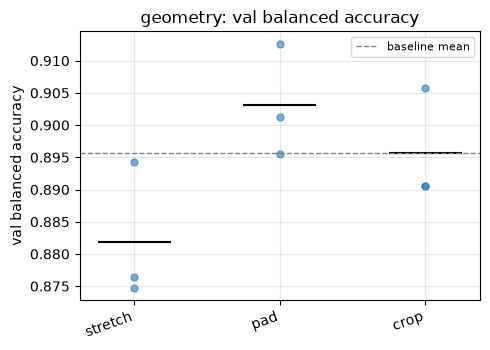

,bal_acc,sd,n,delta,noise_2se,macro_f1,tumor_auc,no_tumor_rec,epochs,params,s/ep
stretch,0.8818,0.0108,3.0,-0.0138,0.0505,0.8722,0.9894,0.8959,39.6667,100244.0,3.8038
pad,0.9031,0.0087,3.0,0.0075,0.0505,0.8939,0.9898,0.9444,49.0000,100244.0,3.7969
crop,0.8956,0.0088,3.0,0.0000,0.0505,0.8879,0.9905,0.9305,60.0000,100244.0,3.8037


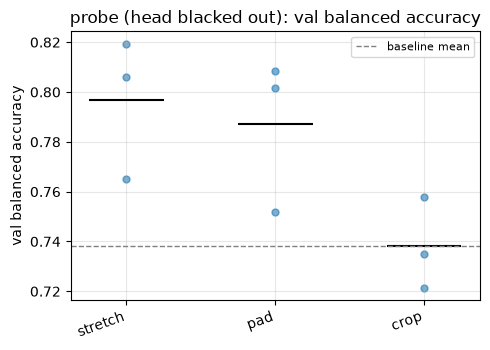

,bal_acc,sd,n,delta,noise_2se,macro_f1,tumor_auc,no_tumor_rec,epochs,params,s/ep
stretch,0.7968,0.0284,3.0,0.0587,0.0505,0.7634,0.9529,0.8958,40.3333,100244.0,3.9665
pad,0.7872,0.0308,3.0,0.0491,0.0505,0.7568,0.9499,0.8715,48.3333,100244.0,4.0613
crop,0.7381,0.0185,3.0,0.0000,0.0505,0.6995,0.9408,0.8611,44.3333,100244.0,4.0724


tie with best val score: ['stretch', 'pad', 'crop'] -> lowest probe score: crop


In [2]:
geo = {"stretch": run_seeds(replace(C5, name="stretch", resize="stretch")),
       "pad": run_seeds(replace(C5, name="pad", resize="pad")),
       "crop": run_seeds(BASE)}
tg = compare(geo, "crop", "geometry: val balanced accuracy"); display(tg)
probe = {g: run_seeds(replace(C5, name=f"probe_{g}", resize=g, probe=True)) for g in ["stretch", "pad", "crop"]}
tp = compare(probe, "crop", "probe (head blacked out): val balanced accuracy"); display(tp)
# validity guard (not a simplicity rule): among geometries within the c4 bar (2*sigma_seed*sqrt(2/3)) of the best val score, take the
# one with the least signal outside the head, so the model is not rewarded for learning a border/scanner shortcut
best = tg.bal_acc.astype(float).max()
ok = [g for g in geo if tg.loc[g, "bal_acc"] >= best - tg.loc[g, "noise_2se"]]
GEOM = min(ok, key=lambda g: tp.loc[g, "bal_acc"])
print("tie with best val score:", ok, "-> lowest probe score:", GEOM)

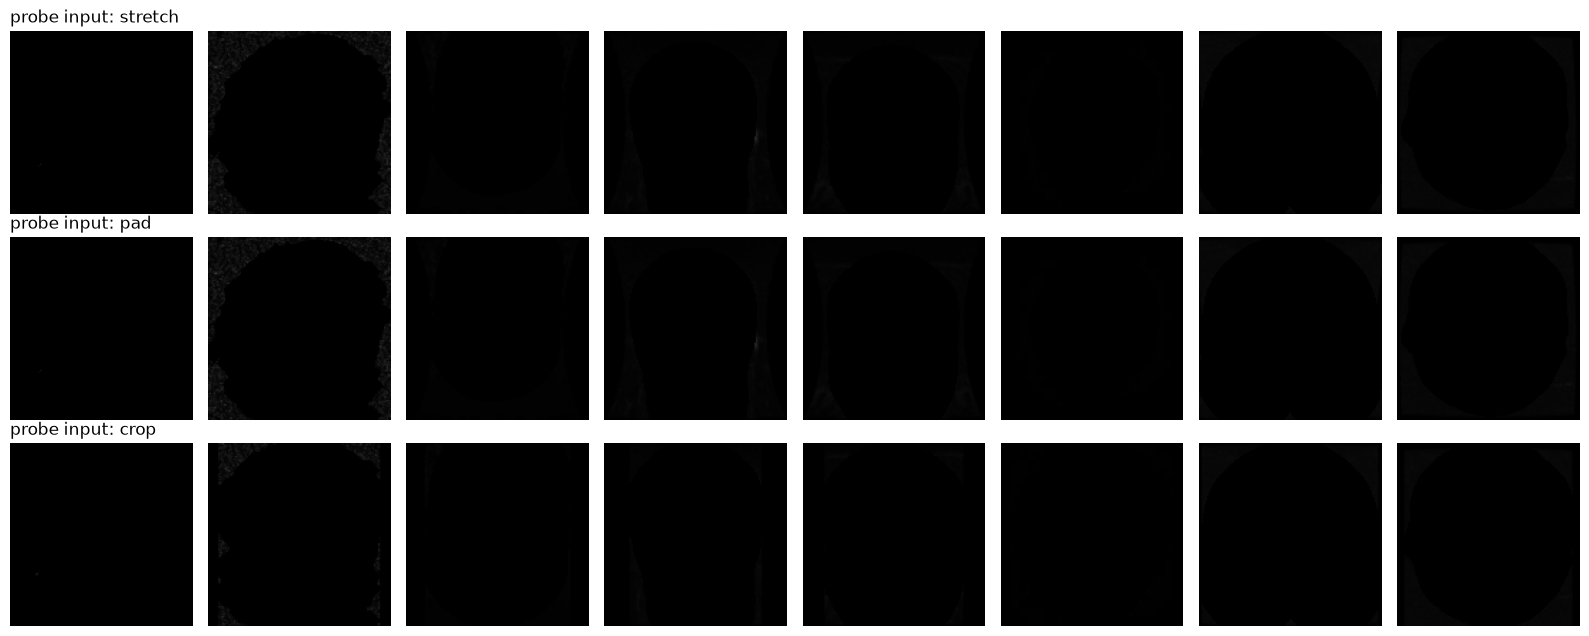

In [3]:
fig, axes = plt.subplots(3, 8, figsize=(16, 6.4))
for r, g in enumerate(["stretch", "pad", "crop"]):
    X = load_split("val", "gray", g, 128, probe=True)["X"]
    for k, i in enumerate(np.linspace(0, len(X) - 1, 8).astype(int)):
        axes[r, k].imshow(X[i, 0], cmap="gray", vmin=0, vmax=255); axes[r, k].axis("off")
    axes[r, 0].set_title(f"probe input: {g}", loc="left")
plt.tight_layout(); plt.show()

**Val score.** stretch 0.882, pad 0.903, crop 0.896 (3 seeds each, sd about 0.009). pad has the highest mean,
by 0.8 pp over crop, well inside the seed noise.

**Probe (head blacked out).** No geometry is close to the 0.25 chance level:
* stretch 0.797, pad 0.787, crop 0.738.

The probe pictures show where that signal comes from. Masking sets the head to exactly 0, but the background
around it is not exactly 0: there is faint sensor noise, JPEG blocks and scanner borders. So the model still sees
the **outline and size of the head** and the **texture of the background**. Both differ by class, because the
no_tumor images come from other sources. Even crop leaves 0.74. Cropping removes most of the border and the
framing, but not the outline.

**Decision: crop to head.** Geometry is the one place where the highest mean does not decide on its own: among
the geometries within the c4 bar of the best val score (2·σ_seed·√(2/3) = 5 pp; all three here), the one with
the least signal outside the head wins. That bar uses σ_seed = 0.031 from the untuned c4 model and is generous:
with the seed sd observed here (about 0.009), stretch (2.1 pp below pad) would not count as within noise. The
pick does not change, because crop is within 0.7 pp of pad either way. This is a validity guard, not a preference for simplicity: pad's 0.8 pp could
come from the border shortcut, and a model that leans on scanner borders would not transfer.

**Caveat carried forward.** A probe of 0.74 means that shortcut signal exists in the inputs. It does *not* say
how much the real model uses it, because that model also sees the head, which is the stronger signal. One way to
remove more of it is to zero everything below the head threshold, so the background becomes truly black. That
was not tested here; it is noted as future work.

*Earlier and later rounds.* r0 (tie rule) also chose crop. r3 (200-epoch cap, all on CUDA): stretch 0.882,
pad 0.912, crop 0.895; crop again, by the same guard.

## 2. Channels

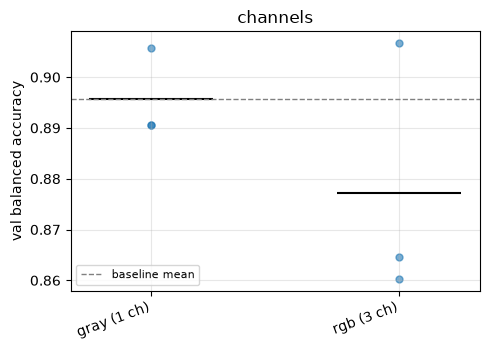

,bal_acc,sd,n,delta,noise_2se,macro_f1,tumor_auc,no_tumor_rec,epochs,params,s/ep
gray (1 ch),0.8956,0.0088,3.0,0.0000,0.0505,0.8879,0.9905,0.9305,60.0,100244.0,3.8037
rgb (3 ch),0.8772,0.0256,3.0,-0.0184,0.0505,0.8596,0.9912,0.9549,50.0,100532.0,4.3720


chosen: gray


In [4]:
ch = {"gray (1 ch)": geo[GEOM], "rgb (3 ch)": run_seeds(replace(C5, name="rgb", mode="rgb", resize=GEOM))}
t = compare(ch, "gray (1 ch)", "channels"); display(t)
MODE = "rgb" if pick(t, "gray (1 ch)") == "rgb (3 ch)" else "gray"; print("chosen:", MODE)

**Result.** Grayscale 0.896 vs RGB 0.877. RGB is lower, 3x noisier across seeds (sd 0.026 vs 0.009) and 15 %
slower. RGB does have a higher no_tumor recall (0.955 vs 0.931). That fits c1: about 4 % of the no_tumor images
are in real colour, which is a shortcut only that class has.

**Decision: grayscale** (highest mean). It also removes a shortcut instead of offering it to the model.

*Other rounds.* Same decision in r0 and r3 (r3: gray 0.895 vs RGB 0.887).

## 3. Normalisation

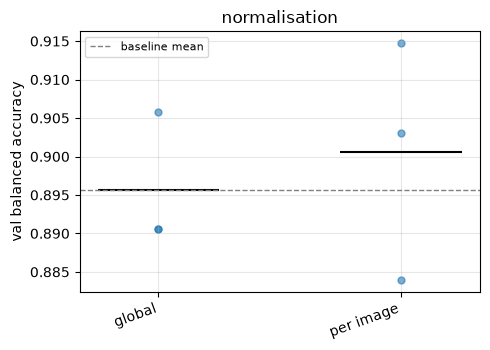

,bal_acc,sd,n,delta,noise_2se,macro_f1,tumor_auc,no_tumor_rec,epochs,params,s/ep
global,0.8956,0.0088,3.0,0.0000,0.0505,0.8879,0.9905,0.9305,60.0,100244.0,3.8037
per image,0.9006,0.0155,3.0,0.0049,0.0505,0.8928,0.9912,0.9167,51.0,100244.0,4.1933


chosen: per_image


In [5]:
nm = {"global": geo[GEOM], "per image": run_seeds(replace(C5, name="perimage", normalize="per_image", resize=GEOM))}
t = compare(nm, "global", "normalisation"); display(t)
NORM = "per_image" if pick(t, "global") == "per image" else "global"; print("chosen:", NORM)

**Result.** Per-image standardisation 0.901 vs global train mean/std 0.896 (+0.5 pp, inside the seed noise).

**Decision: per-image** (highest mean). It is the candidate fix for scanners with different brightness.

**Caveat (found later).** These runs were trained on Apple MPS. Retrained on CUDA as the c6
starting point, the same per-image configuration scored 0.883, below the 0.896 of global. So the choice rested
on a cross-device comparison of two near-equal options. Round r3 retrained every option on CUDA and per-image
won again (0.904 vs global 0.895; 0.907 when retrained as the c6 starting point), so the choice holds, but the difference is small either way.

*Earlier round.* r0 (tie rule) kept global: +0.5 pp was far below the 5 pp the rule required.

## 4. Resolution

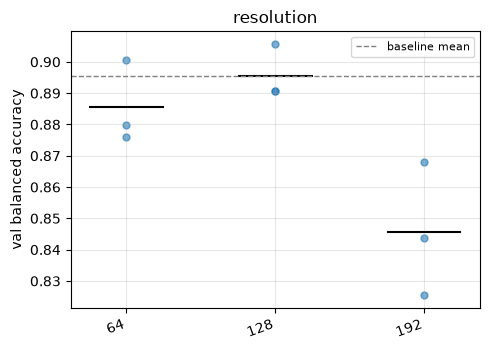

,bal_acc,sd,n,delta,noise_2se,macro_f1,tumor_auc,no_tumor_rec,epochs,params,s/ep
64,0.8855,0.0131,3.0,-0.0101,0.0505,0.8769,0.9880,0.9027,48.0000,100244.0,1.2703
128,0.8956,0.0088,3.0,0.0000,0.0505,0.8879,0.9905,0.9305,60.0000,100244.0,3.8037
192,0.8457,0.0213,3.0,-0.0499,0.0505,0.8392,0.9889,0.8750,42.3333,100244.0,9.0873


{'slope_per_decade': -0.0708, 'slope_ci': (-0.16450081073757583, 0.022893745128228296), 'p_linear': 0.1171, 'p_quadratic': 0.0183, 'has_shape': True, 'best': 128.0, 'best_at_edge': False}
chosen: 128


In [6]:
res = {"64": run_seeds(replace(C5, name="r64", size=64, resize=GEOM)), "128": geo[GEOM],
       "192": run_seeds(replace(C5, name="r192", size=192, resize=GEOM))}
t = compare(res, "128", "resolution"); display(t)
ct = curve_test({int(k): v for k, v in res.items()})   # ordered setting: test the whole curve (rule introduced in c6)
print({k: (round(float(v), 4) if not isinstance(v, (dict, tuple, bool)) else v) for k, v in ct.items() if k != "means"})
SIZE = int(ct["best"]); print("chosen:", SIZE)

**Result.**
* 64 px: 0.886, 3x faster per epoch.
* 128 px: 0.896.
* 192 px: 0.846, and 2.4x slower. Its runs also stopped earlier (42 epochs on average).

**Why more pixels did not help this model.** The model has only 4 pooling stages, 3×3 kernels and global average
pooling. At 192 px each final feature sees a smaller fraction of the brain, and GAP averages more background
positions into the decision. A model needs depth and receptive field to match the resolution, which c7 tests.
So this result is about *this small model*, not about resolution in general.

**Curve test** (all 9 runs, val balanced accuracy against log resolution): significant peak (quadratic term
p = 0.018) at 128 px. The fit is reported as evidence; the value with the highest mean is chosen.

**Decision: 128 px** (highest mean, and the peak of the curve).

*Other rounds.* 128 px in r0 and r3 as well (r3: 64 px 0.892, 192 px 0.880).

## Decisions

| Question | Choice | Result (val bal. acc, 3 seeds) | Reason |
|---|---|---|---|
| Geometry | crop to head | 0.896 (stretch 0.882, pad 0.903) | within the guard's bar of the best (0.7 pp below pad); least shortcut signal (probe 0.74 vs 0.79-0.80) |
| Channels | grayscale | 0.896 vs 0.877 RGB | highest mean; colour is a no_tumor-only shortcut |
| Normalisation | per image | 0.901 vs 0.896 global (0.883 when retrained on CUDA) | highest mean (small; see the cross-device caveat) |
| Resolution | 128 px | 64: 0.886, 192: 0.846 | highest mean, peak of the curve |

**Selection rule.** From this round (r2) on, the option with the highest mean val balanced accuracy wins, whatever
its size or cost. The first rounds (r0 and r1) used the c2/c4 tie rule: a change counted
only if it beat the current choice by more than 2·σ_seed·√(2/3) = 5 pp, otherwise the simpler option was kept.
That bar turned out to be larger than every effect in c5 to c8 (observed seed sd 0.004 to 0.009 once the
models were tuned, against the σ_seed = 0.031 measured on the weak c4 model), so it kept the baseline almost
everywhere. r0 chose global normalisation for that reason.

The chosen input (per-image) differs from the c4 starting point, so c6 retrains its baseline on it: 0.883 on CUDA.
The input format is not where the accuracy is: every option lies within about 2 pp, except 192 px.

In [7]:
INPUT = dict(mode=MODE, resize=GEOM, size=SIZE, normalize=NORM)   # carried into c6
_ = (ARTIFACTS / "input.json").write_text(json.dumps(INPUT))
chosen_runs = run_seeds(replace(C5, name="input_choice", **INPUT)) if INPUT != dict(mode="gray", resize="crop", size=128, normalize="global") else geo["crop"]
print(INPUT, "-> mean val bal. acc", round(log_progress("c5 input", chosen_runs), 4))

{'mode': 'gray', 'resize': 'crop', 'size': 128, 'normalize': 'per_image'} -> mean val bal. acc 0.8828
